# Can global events improve YodaX forecasts across more markets?

The first event model covered Apple and Freeport. Here I test the same idea across the 20-stock watchlist, Tesla, WTI and copper price proxies. I want to know whether event information adds anything beyond price history and market context—not simply whether a more complicated model can fit the past.

This is a **five-session research beta**. It does not predict physical demand, prove causation, or replace the production dashboard model. The global features describe reported event activity; they are not company-specific supply-chain exposure.

The price archive begins in 2015, but the available event archive begins in January 2025. This study uses price context from 2023 and evaluates September 2025–June 2026. It does **not** claim to have learned the 2016 election or COVID from event records. Some dates overlap earlier experiments, so these results are exploratory rather than an untouched holdout.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'config').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data/research-broad-20261025'
RUN = ROOT / 'data/research-runs/broad-global-20261025'
config = json.loads((ROOT / 'config/research-broad.json').read_text())
print(f"{len(config['stocks'])} assets, {config['horizon']}-session horizon")
print('Assets:', ', '.join(config['stocks']))

Matplotlib is building the font cache; this may take a moment.


23 assets, 5-session horizon
Assets: AAPL, MSFT, GOOGL, AMZN, NVDA, META, JPM, BAC, GS, JNJ, UNH, PG, WMT, HD, CAT, DE, XOM, CVX, FCX, NUE, TSLA, CL=F, HG=F


## 1. Collect once, keep the evidence

Prices come from cached Yahoo/yfinance snapshots. GDELT supplies dated daily event archives with source URLs and content hashes. Tesla was added with the same collector. `research_pipeline.broad.prepare` builds a separate dataset; it never overwrites the original two-stock experiment.

The collectors save raw responses and coverage reports. Missing event days stay missing. We do not scrape arbitrary news pages and ask an LLM to invent a historical sentiment series.

The commands below reproduce collection preparation, TimesFM replay and training. Leave them disabled when reviewing this completed run. A fresh run needs the source archive, a new data/output folder and a new frozen candidate identifier; it must not overwrite this model.

In [2]:
REBUILD = False
if REBUILD:
    from research_pipeline.broad import prepare, train
    from research_pipeline.baseline import timesfm_baselines
    new_data = ROOT / 'data/research-broad-new'
    prepare(new_data, ROOT / 'data/research', config)
    timesfm_baselines(pd.read_parquet(new_data / 'prices.parquet'), config, new_data)
    train(new_data, ROOT / 'data/research-runs/broad-new', config,
          artifact_root=ROOT / 'models/shadow/global-new', candidate='global-new')
prices = pd.read_parquet(DATA / 'prices.parquet')
events = pd.read_parquet(DATA / 'events.parquet')
prices.groupby('symbol').agg(first=('date','min'), last=('date','max'), rows=('date','size'))

,first,last,rows
symbol,,,
AAPL,2023-01-03,2026-06-30,875
AMZN,2023-01-03,2026-06-30,875
BAC,2023-01-03,2026-06-30,875
BZ=F,2023-01-03,2026-06-30,878
CAT,2023-01-03,2026-06-30,875
CL=F,2023-01-03,2026-06-30,877
CVX,2023-01-03,2026-06-30,875
DE,2023-01-03,2026-06-30,875
FCX,2023-01-03,2026-06-30,875


## 2. Check coverage before constructing labels

Each target is five XNYS sessions ahead. WTI and copper are daily futures price proxies sampled on that same grid; they are not spot prices or tradable roll-adjusted returns. Historical and live features wait until all input markets have closed, plus an hour.

Duplicate dates, invalid prices and split-crossing contexts are rejected. A missing session cannot quietly shorten the forecast horizon. Every event window needs seven complete archive days, with a two-day availability lag. This is a conservative availability assumption, not a verified historical news timestamp.

In [3]:
features = pd.read_parquet(RUN / 'features.parquet')
assert not prices.duplicated(['symbol','date']).any()
assert not features.duplicated(['symbol','date']).any()
quality = pd.DataFrame({
    'feature_rows': features.groupby('symbol').size(),
    'settled_targets': features.groupby('symbol').target_return.count(),
    'complete_event_rows': features.assign(complete=features.event_coverage_7d.eq(1)).groupby('symbol').complete.sum(),
})
display(quality)
display(features[['return_5','volatility_20','volume_ratio','event_log_count_7d',
                  'material_conflict_share_7d','material_cooperation_share_7d']].describe())

,feature_rows,settled_targets,complete_event_rows
symbol,,,
AAPL,373,368,353
AMZN,373,368,353
BAC,373,368,353
CAT,373,368,353
CL=F,373,368,353
CVX,373,368,353
DE,373,368,353
FCX,373,368,353
GOOGL,373,368,353


,return_5,volatility_20,volume_ratio,event_log_count_7d,material_conflict_share_7d,material_cooperation_share_7d
count,8424.000000,8424.000000,8424.000000,7974.000000,7974.000000,7974.000000
mean,0.004440,0.019279,1.015564,13.580780,0.138711,0.114203
std,0.047209,0.009592,0.539790,0.104595,0.008580,0.005409
min,-0.290490,0.005784,0.000000,13.156879,0.121917,0.098648
25%,-0.021212,0.012971,0.769326,13.514554,0.132194,0.110888
50%,0.005023,0.016837,0.926524,13.604601,0.137408,0.113966
75%,0.030013,0.022469,1.144702,13.647532,0.143136,0.117583
max,0.356312,0.075753,14.048009,13.748449,0.172069,0.130109


## 3. Use the same preprocessing in training and inference

TimesFM supplies the price-history baseline. A small gradient-boosted tree model learns its remaining return error. Inputs include recent returns, volatility, volume, SPY/WTI/copper context, and an asset indicator. The event version also sees global event volume and cooperation/conflict shares.

The market-only and event versions use the same tree settings and evaluation rows. Median imputation and asset encoding are fitted inside the saved sklearn pipeline. Future targets never enter its feature columns. The original country-linked model remains a separate experiment.

In [4]:
from research_pipeline.features import MARKET_FEATURES, EVENT_FEATURES
from research_pipeline.evaluate import chronological_split
eligible = features[features.event_coverage_7d.eq(1)].dropna(subset=['target_return'])
splits = []
for start, end in config['validation_windows']:
    train_rows, test_rows = chronological_split(eligible, start, end)
    assert train_rows.target_date.max() < test_rows.date.min()
    assert set(config['stocks']) == set(train_rows.symbol) == set(test_rows.symbol)
    splits.append(dict(start=start, end=end, train=len(train_rows), test=len(test_rows),
                       last_training_target=str(train_rows.target_date.max().date())))
display(pd.DataFrame(splits))
print('Numerical columns:', MARKET_FEATURES + EVENT_FEATURES)
print('Categorical column: symbol; fitted on training rows only')

,start,end,train,test,last_training_target
0,2025-09-01,2026-01-01,3075,1840,2025-08-29
1,2026-01-01,2026-07-01,5030,2714,2025-12-31


Numerical columns: ['baseline_return', 'return_1', 'return_5', 'return_20', 'volatility_20', 'volume_ratio', 'market_return_5', 'oil_return_5', 'copper_return_5', 'event_log_count_7d', 'material_conflict_share_7d', 'material_cooperation_share_7d', 'event_coverage_7d']
Categorical column: symbol; fitted on training rows only


## 4. Compare against simple alternatives

The primary question is event-adjusted versus market-adjusted error. We also compare with raw TimesFM and no price change. MAE is measured in return percentage points; lower is better. A 20-session moving-block bootstrap keeps assets together and accounts for overlapping targets. It does not turn observational associations into causal effects.

I fixed the tree settings before this wider run. There is no random train/test split, test-set tuning or claim that the final refit was independently tested on these same historical rows.

,period,model,observations,mae_return_pp,rmse_return_pp,direction_accuracy
0,2025-09-01,event_adjusted,1840,2.867270,3.848807,0.542391
1,2025-09-01,market_adjusted,1840,3.089798,4.264443,0.453261
2,2025-09-01,no_change,1840,2.796054,3.831455,0.000543
3,2025-09-01,timesfm,1840,2.867998,3.920540,0.497826
4,2026-01-01,event_adjusted,2714,3.861069,5.113320,0.537583
5,2026-01-01,market_adjusted,2714,4.013745,5.218479,0.481945
6,2026-01-01,no_change,2714,3.815079,5.006651,0.000368
7,2026-01-01,timesfm,2714,4.000257,5.277597,0.484156


,period,status,dates,block_sessions,valid_blocks,mean_improvement_pp,ci95_pp,interpretation
0,2025-09-01,computed,80,20,61,0.222527,"[-0.118245, 0.674562]",Positive favors candidate; dependence-aware in...
1,2026-01-01,computed,118,20,99,0.152676,"[0.063783, 0.230022]",Positive favors candidate; dependence-aware in...


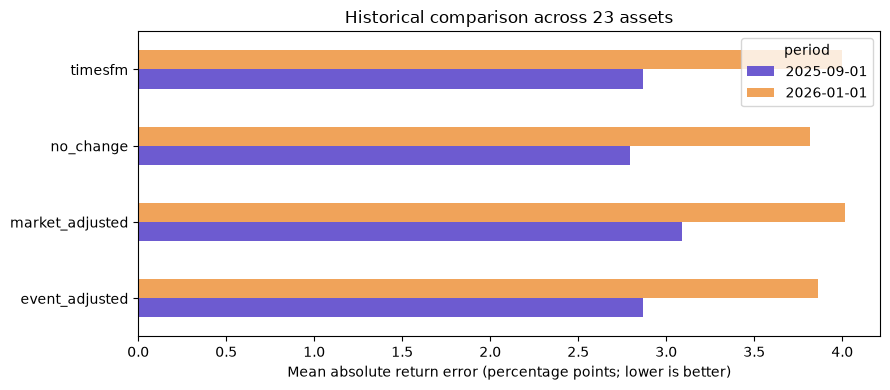

In [5]:
report = json.loads((RUN / 'report.json').read_text())
metrics = pd.DataFrame([dict(period=f['start'], **m) for f in report['folds'] for m in f['metrics']])
display(metrics[['period','model','observations','mae_return_pp','rmse_return_pp','direction_accuracy']])
display(pd.DataFrame([dict(period=f['start'], **f['uncertainty']) for f in report['folds']]))
chart = metrics.pivot(index='model', columns='period', values='mae_return_pp')
chart.plot.barh(color=['#6d5bd0','#f0a35a'], figsize=(9,4))
plt.xlabel('Mean absolute return error (percentage points; lower is better)')
plt.ylabel(''); plt.title('Historical comparison across 23 assets'); plt.tight_layout(); plt.show()

## 5. Look below the pooled average

A good pooled result can hide weak assets. The table below shows errors by asset and period. The saved per-asset report also includes confidence intervals and feature mean shifts. These shifts are diagnostics, not a guarantee that drift has been removed.

The selected present-day companies introduce survivorship and selection bias. News coverage is uneven across countries and languages. Futures rolls, vendor restatements and possible TimesFM pretraining overlap remain limitations.

In [6]:
asset_report = json.loads((RUN / 'per-asset-evaluation.json').read_text())
asset_metrics = pd.DataFrame([dict(symbol=a['symbol'], fold=a['fold'], **m)
                              for a in asset_report for m in a['metrics']])
display(asset_metrics.pivot(index=['symbol','fold'], columns='model', values='mae_return_pp').round(3))
shift = pd.DataFrame([dict(symbol=a['symbol'], fold=a['fold'], feature=k, **v)
                      for a in asset_report for k,v in a['feature_shift'].items()])
display(shift.assign(magnitude=shift.standardized_mean_difference.abs()).nlargest(10,'magnitude'))

model        event_adjusted  market_adjusted  no_change  timesfm
symbol fold                                                     
AAPL   0              2.497            2.859      2.424    2.577
       1              2.767            3.173      2.918    3.132
AMZN   0              3.337            3.520      3.268    3.196
       1              4.037            4.027      3.877    4.040
BAC    0              1.808            2.247      1.953    1.923
       1              2.958            3.197      3.028    3.060
CAT    0              3.464            4.139      3.780    4.010
       1              3.805            4.505      4.161    4.817
CL=F   0              2.942            2.687      2.500    2.444
       1              7.767            7.470      7.408    8.050
CVX    0              1.967            1.737      1.514    1.483
       1              3.131            3.083      3.072    3.283
DE     0              2.235            2.112      1.900    1.791
       1              3.686            4.242      4.006    4.166
FCX    0              4.879            4.978      4.836    4.732
       1              6.211            6.846      6.810    6.779
GOOGL  0              3.407            3.953      3.489    3.673
       1              4.034            4.085      3.835    3.934
GS     0              2.770            3.174      2.816    2.914
       1              2.967            3.469      3.263    3.353
HD     0              2.994            2.713      2.557    2.498
       1              3.155            3.288      3.047    3.076
HG=F   0              2.403            2.819      2.628    2.683
       1              3.140            3.330      3.101    3.006
JNJ    0              2.142            2.354      2.107    2.201
       1              2.604            2.587      2.534    2.597
JPM    0              2.034            2.272      2.137    2.104
       1              2.536            2.727      2.514    2.664
META   0              3.661            3.664      3.373    3.498
       1              4.425            4.306      4.202    4.122
MSFT   0              2.055            2.340      1.971    2.279
       1              4.232            3.877      3.883    3.962
NUE    0              3.209            3.502      3.046    3.208
       1              4.060            4.481      4.380    4.282
NVDA   0              3.466            3.808      3.675    3.721
       1              4.611            4.702      3.980    4.918
PG     0              2.385            2.007      1.720    1.771
       1              2.395            2.673      2.319    2.472
TSLA   0              4.619            5.753      4.981    5.128
       1              4.669            4.510      4.166    4.259
UNH    0              3.520            3.738      3.469    3.827
       1              4.813            4.888      4.672    5.009
WMT    0              2.204            2.597      2.267    2.508
       1              3.032            3.125      2.922    2.990
XOM    0              1.950            2.092      1.899    1.796
       1              3.770            3.725      3.647    4.035

,symbol,fold,feature,training_mean,evaluation_mean,standardized_mean_difference,magnitude
56,NVDA,0,volatility_20,0.016614,0.022026,5.848931,5.848931
576,CL=F,1,volatility_20,0.018412,0.039087,4.093127,4.093127
572,CL=F,1,baseline_return,0.005275,-0.022195,-3.065169,3.065169
61,NVDA,0,event_log_count_7d,13.615332,13.579106,-2.305929,2.305929
351,NVDA,1,baseline_return,-0.004232,-0.016329,-2.236901,2.236901
55,NVDA,0,return_20,0.113984,0.002702,-2.077342,2.077342
308,AAPL,1,event_log_count_7d,13.632696,13.507712,-1.918136,1.918136
321,MSFT,1,event_log_count_7d,13.632696,13.507712,-1.918136,1.918136
334,GOOGL,1,event_log_count_7d,13.632696,13.507712,-1.918136,1.918136
347,AMZN,1,event_log_count_7d,13.632696,13.507712,-1.918136,1.918136


## 6. Save a candidate, not a victory claim

The event model reduced pooled error against the market-only adjustment in both windows. The first confidence interval includes zero. In the second window, the interval favors events. **No price change still had lower pooled MAE than the event model in both windows.** That is a reason to keep this experimental.

After the comparisons, I refit preprocessing and each adjustment model once on all eligible settled rows through June 2026. The resulting artifacts are frozen, checksummed and assessed prospectively. Their training metadata distinguishes them from the fold models above. No TimesFM weights were fine-tuned.

In [7]:
from research_pipeline.model import load_bundle
from hashlib import sha256
candidate = json.loads((ROOT / 'config/shadow-broad.json').read_text())
for name, spec in candidate['artifacts'].items():
    folder = ROOT / spec['path']
    assert sha256((folder / 'pipeline.joblib').read_bytes()).hexdigest() == spec['sha256']
    model = load_bundle(folder)
    values = model.predict_features(eligible.tail(23))
    assert np.isfinite(values).all()
    print(name, model.metadata['training_start'], model.metadata['last_training_target'],
          model.metadata['rows'], 'settled training rows')
print('Role: experimental chat beta; no automatic production promotion')

market_adjusted 2025-01-08 2026-06-30 7859 settled training rows
event_adjusted 2025-01-08 2026-06-30 7859 settled training rows
Role: experimental chat beta; no automatic production promotion


## 7. What the deployed chat actually does

Gemini resolves the question to a supported asset and horizon, researches sources, and queues the request. The numerical worker independently collects prices and dated GDELT archives, runs this same feature builder and the frozen models, then saves the prediction, input values, source hashes, model revision and target date. Chat can explain those saved outputs and show the recorded inputs.

Five-session requests for these 23 assets use the event beta. Other supported horizons use TimesFM. Missing current inputs leave event requests queued; there is no silent model substitution. Outcomes are scored after their target market closes, without rewriting the original prediction.

Newly discussed headlines are still qualitative research context. A two-day GDELT lag is explicit, and a novel headline does not rewrite a forecast. We have not trained numerical demand forecasts or added benchmark histories for silicon, lithium and steel. These remain research-only.

Next evidence to collect: prospective error versus TimesFM, market adjustment and no change, by asset; missing-data rates; source age; feature drift; and stable improvement over enough independent dates. Retraining is a separate candidate experiment, never an automatic reward or penalty applied to published values.